# Model Visualization

There are cases where visualizing the model may be helpful in debugging or communicating the model with others. It may be beneficial to visualize the model in .png or .pdf format instead of the text that is printed when the model is instantiated. The mol-miner-graphs has wrapped torchviz to generate an image of the model.

## Import Modules

In [1]:
import pandas as pd
from mminer_graphs import MolToGraph
from tqdm import tqdm
from mminer_graphs.model import GCNNet, GINENet, EarlyStopping, GSAGENet, GATNet
from mminer_graphs import Plots
from torch_geometric.loader import DataLoader
from mminer_graphs.model.model_utils import set_seed
from mminer_graphs.plot import Plots

## Dataset prep

The dataset will need to be prepared. While the example shows the preparation of both the train and test dataset, only one is needed when generating the model image.

In [2]:
data = pd.read_csv("dataset/bace.csv")
cols = ['CID', 'smiles', 'Class', 'Model']
dataset = data[cols]
print(f"The shape of the dataset: {dataset.shape}")
dataset.head()

The shape of the dataset: (1513, 4)


,CID,smiles,Class,Model
0,BACE_1,O1CC[C@@H](NC(=O)[C@@H](Cc2cc3cc(ccc3nc2N)-c2c...,1,train
1,BACE_2,Fc1cc(cc(F)c1)C[C@H](NC(=O)[C@@H](N1CC[C@](NC(...,1,train
2,BACE_3,S1(=O)(=O)N(c2cc(cc3c2n(cc3CC)CC1)C(=O)N[C@H](...,1,train
3,BACE_4,S1(=O)(=O)C[C@@H](Cc2cc(O[C@H](COCC)C(F)(F)F)c...,1,train
4,BACE_5,S1(=O)(=O)N(c2cc(cc3c2n(cc3CC)CC1)C(=O)N[C@H](...,1,train


Convert the data into molecular graphs. The information will need to be loaded into the DataLoader class from torch_geometric.

In [3]:
train = dataset[dataset.iloc[:, -1] == 'train']
test = dataset[dataset.iloc[:, -1] == 'test']

train_graphs = [MolToGraph(smi=smi, label=y).graph_data for smi, y in tqdm(zip(train.smiles, train.Class), desc="Converting Train Graphs")]
test_graphs = [MolToGraph(smi=smi, label=y).graph_data for smi, y in tqdm(zip(test.smiles, test.Class), desc="Converting Test Graphs")]

# load data
train_graphs = DataLoader(train_graphs, batch_size=1024, shuffle=True, worker_init_fn=set_seed(42)) # avoid overfitting to sample order
test_graphs = DataLoader(test_graphs, batch_size=1024)

Converting Train Graphs: 1376it [00:02, 529.90it/s]
Converting Test Graphs: 137it [00:00, 531.40it/s]


### Instantiate the Model
The model will need to be instantiated. In this example, the GINENet model will be used.

In [4]:
model = GINENet(node_dim=142, edge_feat_dim=16, hidden_dim=128, graph_layers=3, mlp_layers=2, reduce_graph=False, graph_dropout= 0, mlp_dropout=0, num_classes=2)
model

GINENet(
  (gine_conv): ModuleList(
    (0): GINEConv(nn=Sequential(
      (0): Linear(in_features=142, out_features=128, bias=True)
      (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Linear(in_features=128, out_features=128, bias=True)
      (4): ReLU()
    ))
    (1-2): 2 x GINEConv(nn=Sequential(
      (0): Linear(in_features=128, out_features=128, bias=True)
      (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Linear(in_features=128, out_features=128, bias=True)
      (4): ReLU()
    ))
  )
  (mlp): ModuleList(
    (0): Sequential(
      (0): Linear(in_features=128, out_features=64, bias=True)
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Dropout(p=0, inplace=False)
    )
  )
  (final_mlp): Linear(in_features=64, out_features=2, bias=True)
)

Dataset check.

In [5]:
train_graphs.dataset[0]

Data(x=[32, 142], edge_index=[2, 70], edge_attr=[70, 16], y=[1])

## Plot

To create the model diagram, the **Plots()** class will need to be instantiated. The model and the training dataset is needed as the parameter. It can be given upon the **Plots()** class instantiation, or to the **plot_model()** method. Finally, to save the model, the savepath and figtype should be set. The savepath will designate where the diagram is saved, while the figtype will determine the figure type (.pdf or .png).

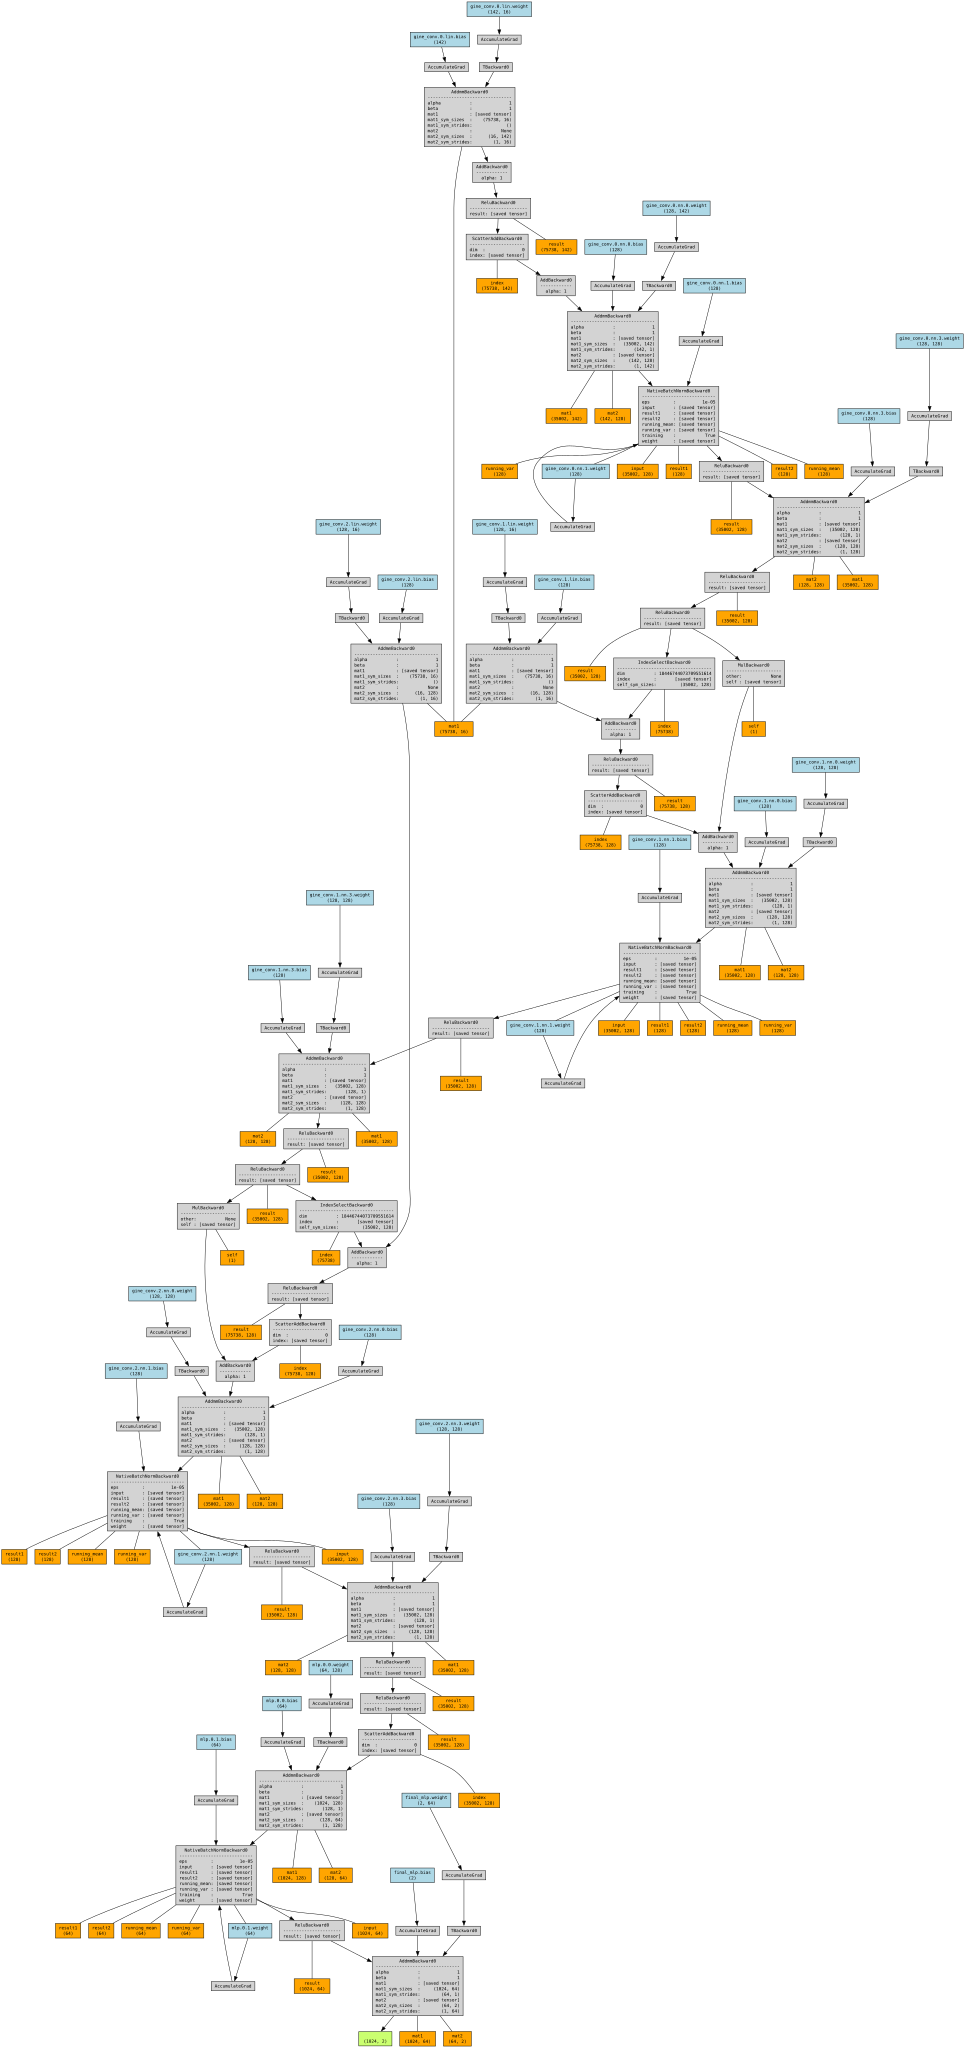

In [6]:
plot = Plots(model, train_graphs)

plot.plot_model(savepath="img/figure", figtype="png")